## 📈 Market-Implied Team Strengths: Does Learning from the Betting Odds Improve the Forecasts?
### *(Backtest of the change to the Football League Simulator's team ratings, October 2026)*

**Competitions:** Premier League, Championship, Serie A, La Liga, Bundesliga, Ligue 1, Eredivisie, and Primeira Liga\
**Question:** if each team's attack and defence ratings also learn from recent betting prices, do the forecasts get better for matches the bookmakers haven't priced yet?\
**Methods:** Poisson goal model, working backwards from odds to expected goals, weighted ridge regression, out-of-sample backtest\
**Author:** [Victoria Friss de Kereki](https://www.linkedin.com/in/victoria-friss-de-kereki/)\
**Live results (updated daily, all 9 leagues):** [football-league-simulator.streamlit.app](https://football-league-simulator.streamlit.app/)\
**Code:** [github.com/vickyfriss/football-league-predictions](https://github.com/vickyfriss/football-league-predictions)\
**Companion notebook:** `202610 - 1 - Predicting Football League Positions (Masterclass Edition).ipynb`\
**Last updated:** `20/10/2026`

### Why look at this?

The simulator already uses the betting market, but only match by match: wherever bookmakers have priced a game, their de-vigged probabilities replace the model's. The catch is that they only price the next matchday or two. On 19 October, only 21 of the 311 Premier League games left had odds. So for 93% of the season, what the market knows (transfers, a new manager, an injury crisis) never reached the forecast.

The idea here is to work **backwards** from those prices to each team's strength:

1. **Price → expected goals.** For each priced match, find the two expected-goals numbers (λ home, λ away) whose Poisson scoreline grid gives the market's home/draw/away probabilities. It's the model's usual grid, run in reverse.
2. **Expected goals → ratings.** The model says `log λ = log(league average) [+ home advantage] + log(attack) + log(opponent's defence)`. Fitting that across the last six weeks of prices (recent ones count more) gives a market-implied attack and defence for every team.
3. **Blend.** Mix the market-implied ratings with the usual goal-based ones, so the market's view also reaches every unpriced fixture.

The question is simple: **does it actually forecast better?** This notebook tests it on real data, using the production code itself.

### 1. Setup

Everything comes from the production repo, `football-league-predictions`, cloned next to this one. The functions tested here are the ones that run every morning: `compute_final_probabilities`, `market_implied_ratings`, and `blend_ratings` in `3_probabilities.py`. The odds history is `data/odds_history/`, which the daily run adds to. It was seeded from the odds file saved by every daily run since 7 March 2026.

In [1]:
import importlib.util, io, os, contextlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
REPO = os.path.abspath(os.path.join(os.getcwd(), "..", "football-league-predictions"))

def load_module(name, file):
    spec = importlib.util.spec_from_file_location(name, os.path.join(REPO, file))
    module = importlib.util.module_from_spec(spec)
    with contextlib.redirect_stdout(io.StringIO()):
        spec.loader.exec_module(module)
    return module

probabilities = load_module("probabilities", "3_probabilities.py")
processing = load_module("processing", "2_dataset_processing.py")

LEAGUES = ["premierleague_england", "championship_england", "seriea_italy", "laliga_spain",
           "bundesliga_germany", "ligue1_france", "eredivisie_netherlands", "primeiraliga_portugal"]
print("Production market weight:", probabilities.MARKET_WEIGHT,
      "| window:", probabilities.MARKET_WINDOW_DAYS, "days | half-life:", probabilities.MARKET_HALF_LIFE_DAYS, "days")

Production market weight: 0.25 | window: 42 days | half-life: 21 days


### 2. Data

* **Odds history:** one row per daily snapshot and match, with the de-vigged probabilities. The files keep the betting API's raw team names (e.g. "Brighton and Hove Albion"), so they get the same name mapping production applies.
* **Results:** football-data.org results for 2024/25, 2025/26, and 2026/27, with the same mapping.

Brazil is left out, because its calendar-year season doesn't line up with the European ones.

In [2]:
def load_odds_history(league):
    df = pd.read_csv(os.path.join(REPO, "data", "odds_history", f"{league}.csv"))
    df["snap_time"] = pd.to_datetime(df["snap_time"], utc=True).dt.tz_localize(None)
    df = df.rename(columns={"home_team": "homeTeam", "away_team": "awayTeam"})
    mapping = processing.mappings.get(league, {})
    df[["homeTeam", "awayTeam"]] = df[["homeTeam", "awayTeam"]].replace(mapping)
    return df

_results = {}
def results(league, season):
    # season 2025 = 2025/26, as in the repo's file names
    if (league, season) not in _results:
        path = os.path.join(REPO, "data", f"past_{league}_{season}.csv")
        if not os.path.exists(path):
            _results[(league, season)] = pd.DataFrame(columns=["utcDate", "homeTeam", "awayTeam", "homeGoals", "awayGoals"])
        else:
            df = pd.read_csv(path)
            df = df[df["status"] == "FINISHED"].dropna(subset=["homeGoals", "awayGoals"])
            df = processing.normalize_columns(df).replace(processing.mappings.get(league, {}))
            df["utcDate"] = pd.to_datetime(df["utcDate"], utc=True).dt.tz_localize(None)
            _results[(league, season)] = df.sort_values("utcDate").reset_index(drop=True)
    return _results[(league, season)]

odds = {lg: load_odds_history(lg) for lg in LEAGUES}
summary = pd.DataFrame({lg: {"snapshots": o["snap_time"].nunique(), "match prices": len(o),
                             "from": o["snap_time"].min().date(), "to": o["snap_time"].max().date()} for lg, o in odds.items()}).T
summary

,snapshots,match prices,from,to
premierleague_england,132,2294,2026-03-07,2026-10-20
championship_england,115,1662,2026-04-01,2026-10-20
seriea_italy,133,2196,2026-03-07,2026-10-20
laliga_spain,133,2418,2026-03-07,2026-10-20
bundesliga_germany,130,1801,2026-03-07,2026-10-20
ligue1_france,132,1822,2026-03-07,2026-10-20
eredivisie_netherlands,93,1093,2026-04-20,2026-10-20
primeiraliga_portugal,49,421,2026-08-19,2026-10-20


A quick check before anything else: every team name in the odds needs to match a team in the results, or the market's view of that team would silently go nowhere. (The first version of this test missed exactly that: the odds files use the API's raw names.)

In [3]:
unmatched = {}
for lg, o in odds.items():
    known = set().union(*[set(results(lg, s)["homeTeam"]) for s in (2025, 2026)])
    missing = sorted((set(o["homeTeam"]) | set(o["awayTeam"])) - known)
    if missing:
        unmatched[lg] = missing
unmatched or "every odds team name matches the results"

{'ligue1_france': ['Saint Etienne']}

The only name left is Saint-Étienne, which appears in the odds but in none of the Ligue 1 results on file, so it doesn't affect the test.

### 3. Rebuilding the ratings as of any past date

To be fair, each forecast can only use what was known **on that day**. This rebuilds exactly what production would have seen: the previous season plus this season's results up to that date (the "blended" input), this season alone for the shrinkage, and odds snapshots up to that date. The ratings then come straight from `compute_final_probabilities`, which returns both the goals-only and the market-implied ratings.

First, a sanity check: rebuilt as of 19 October, the goals-only forecast for Aston Villa v Manchester City should match what the live dashboard showed that morning (30% / 22% / 48%).

In [4]:
def season_of(date):
    return 2025 if date < pd.Timestamp("2026-07-15") else 2026

def ratings_as_of(league, date):
    season = season_of(date)
    current = results(league, season)
    current = current[current["utcDate"] < date]
    blended = pd.concat([results(league, season - 1), current], ignore_index=True)
    rosters = {lg: {s: set(pd.unique(results(lg, s)[["homeTeam", "awayTeam"]].values.ravel("K"))) for s in (season - 1, season)}
               for lg in {"premierleague_england", league}}
    with contextlib.redirect_stdout(io.StringIO()):
        _, ratings, _ = probabilities.compute_final_probabilities(
            [league], {league: blended}, {league: pd.DataFrame({"homeTeam": ["placeholder"], "awayTeam": ["placeholder"]})}, {league: pd.DataFrame()},
            current_season_matches_dict={league: current}, prior_rosters_by_league_season=rosters,
            odds_history_dict={league: odds[league]}, as_of=date)
    return ratings[league]

def forecast(home, away, r, weight):
    if r["attack_market"] is None:
        attack, defence = r["attack_goals"], r["defense_goals"]
    else:
        attack = probabilities.blend_ratings(r["attack_goals"], r["attack_market"], weight)
        defence = probabilities.blend_ratings(r["defense_goals"], r["defense_market"], weight)
    p = np.array(probabilities.match_probabilities_league(home, away, attack, defence, r["league_avg"], r["home_adv"]))
    return p / p.sum()

r = ratings_as_of("premierleague_england", pd.Timestamp("2026-10-19 09:00"))
print("Goals-only, as of 19 Oct:  ", (100 * forecast("Aston Villa", "Manchester City", r, 0.0)).round(1))
print("With 25% market, as of 19 Oct:", (100 * forecast("Aston Villa", "Manchester City", r, 0.25)).round(1))
print("Market's own price that week: 21.8 / 23.0 / 55.2")

Goals-only, as of 19 Oct:   [29.9 22.3 47.7]
With 25% market, as of 19 Oct: [28.4 22.7 48.9]
Market's own price that week: 21.8 / 23.0 / 55.2


The goals-only rebuild matches the dashboard to the decimal. Blending in a quarter of the market's view moves the forecast towards the bookmakers' price, without simply copying it.

### 4. The backtest

* **When:** every Tuesday through the end of last season (10 March to 19 May 2026), and through this season so far (25 August to 13 October 2026).
* **What gets forecast:** only matches the market **hadn't priced yet** on that day, and then priced within the next four weeks. These are exactly the matches where the new idea could help.
* **Scored against:**
  * the market's price when it first appeared, as **RMSE** (how far the model's three probabilities sit from the market's); and
  * the **actual result**, as the **Brier score** (squared gap between the probabilities and what happened) and **log loss**. Lower is better for all three.
* **Fair test:** the blend weight is chosen on 2025/26 only, then judged unchanged on 2026/27.

In [5]:
WEIGHTS = [0.0, 0.25, 0.5, 0.75, 1.0]
EVAL_DATES = {2025: pd.date_range("2026-03-10 10:00", "2026-05-19 10:00", freq="7D"),
              2026: pd.date_range("2026-08-25 10:00", "2026-10-13 10:00", freq="7D")}

rows = []
for season, dates in EVAL_DATES.items():
    for lg in LEAGUES:
        if season == 2025 and lg == "primeiraliga_portugal":
            continue  # no 2024/25 results on file to blend with
        o = odds[lg][odds[lg]["snap_time"].map(season_of) == season]
        if o.empty:
            continue
        first_price = o.sort_values("snap_time").groupby(["homeTeam", "awayTeam"]).head(1).set_index(["homeTeam", "awayTeam"])
        played_all = results(lg, season)
        outcome = {(m.homeTeam, m.awayTeam): 0 if m.homeGoals > m.awayGoals else 1 if m.homeGoals == m.awayGoals else 2
                   for m in played_all.itertuples()}
        for D in dates:
            known = o[o["snap_time"] <= D]
            if known.empty:
                continue
            latest = known[known["snap_time"] == known["snap_time"].max()]
            priced_now = set(zip(latest["homeTeam"], latest["awayTeam"]))
            played = played_all[played_all["utcDate"] < D]
            played = set(zip(played["homeTeam"], played["awayTeam"]))
            targets = first_price[(first_price["snap_time"] > D) & (first_price["snap_time"] <= D + pd.Timedelta(days=28))]
            targets = targets[[k not in priced_now and k not in played for k in targets.index]]
            if targets.empty:
                continue
            r = ratings_as_of(lg, D)
            if r["attack_market"] is None:
                continue
            for (h, a), t in targets.iterrows():
                row = {"season": season, "league": lg, "date": D, "home": h, "away": a,
                       "days_ahead": (t["snap_time"] - D).days, "outcome": outcome.get((h, a)),
                       "market": np.array([t["p_home_book"], t["p_draw_book"], t["p_away_book"]])}
                for w in WEIGHTS:
                    row[w] = forecast(h, a, r, w)
                rows.append(row)
bt = pd.DataFrame(rows)
print(f"{len(bt):,} forecasts of {bt[['season', 'league', 'home', 'away']].drop_duplicates().shape[0]:,} matches, "
      f"{bt['outcome'].notna().sum():,} with a result so far")

3,201 forecasts of 988 matches, 2,624 with a result so far


### 5. Results

Some matches are forecast from more than one Tuesday, so the confidence intervals resample whole **matches**, not single rows. That way they don't overstate how sure the result is.

In [6]:
def scores(df):
    M = np.stack(df["market"]); has = df["outcome"].notna().to_numpy()
    Y = np.zeros_like(M); Y[has, df.loc[has, "outcome"].astype(int)] = 1
    out = {}
    for name, P in [*[(w, np.stack(df[w])) for w in WEIGHTS], ("market itself", M)]:
        out[name] = {"RMSE vs market": np.sqrt(((P - M) ** 2).mean()),
                     "Brier": ((P - Y) ** 2).sum(1)[has].mean(),
                     "log loss": -np.log(np.clip((P * Y).sum(1), 1e-9, 1))[has].mean()}
    t = pd.DataFrame(out).T
    t.index = [f"{int(100 * i)}% market" if isinstance(i, float) else i for i in t.index]
    t.loc["market itself", "RMSE vs market"] = np.nan
    return t.round(4)

tuning, test = bt[bt["season"] == 2025], bt[bt["season"] == 2026]
print("TUNING SET: 2025/26, March to May"); display(scores(tuning))
print("TEST SET: 2026/27, August to October"); display(scores(test))

TUNING SET: 2025/26, March to May


,RMSE vs market,Brier,log loss
0% market,0.0706,0.6181,1.0328
25% market,0.0654,0.6165,1.0295
50% market,0.0673,0.6175,1.0311
75% market,0.0741,0.6205,1.0368
100% market,0.0837,0.6252,1.0461
market itself,NaN,0.6074,1.0157


TEST SET: 2026/27, August to October


,RMSE vs market,Brier,log loss
0% market,0.0764,0.6115,1.0212
25% market,0.0642,0.6036,1.0093
50% market,0.0540,0.5974,0.9998
75% market,0.0464,0.5927,0.9924
100% market,0.0422,0.5895,0.9868
market itself,NaN,0.5871,0.9838


In [7]:
best = min(WEIGHTS, key=lambda w: scores(tuning).loc[f"{int(100 * w)}% market", "Brier"])
print(f"Weight chosen on the tuning set (lowest Brier): {int(100 * best)}% market")

def paired_ci(df, w, B=2000, seed=0):
    # Brier of the blend minus Brier of goals-only, resampling whole matches
    d = df[df["outcome"].notna()]
    Y = np.zeros((len(d), 3)); Y[np.arange(len(d)), d["outcome"].astype(int)] = 1
    diff = ((np.stack(d[w]) - Y) ** 2).sum(1) - ((np.stack(d[0.0]) - Y) ** 2).sum(1)
    groups = d[["league", "home", "away"]].astype(str).agg("|".join, axis=1).to_numpy()
    _, g = np.unique(groups, return_inverse=True)
    sums, counts = np.bincount(g, diff), np.bincount(g)
    rng = np.random.default_rng(seed)
    boot = [(sums[i].sum() / counts[i].sum()) for i in (rng.integers(0, len(sums), len(sums)) for _ in range(B))]
    return diff.mean(), np.percentile(boot, [2.5, 97.5])

est, (lo, hi) = paired_ci(test, best)
print(f"TEST SET, {int(100 * best)}% market vs goals-only: Brier {est:+.4f} (95% CI {lo:+.4f} to {hi:+.4f})")

Weight chosen on the tuning set (lowest Brier): 25% market
TEST SET, 25% market vs goals-only: Brier -0.0079 (95% CI -0.0110 to -0.0051)


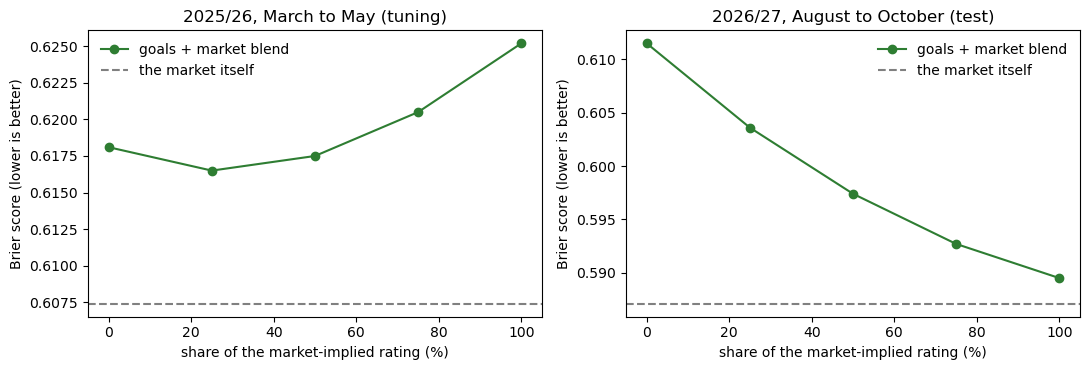

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (label, df) in zip(axes, [("2025/26, March to May (tuning)", tuning), ("2026/27, August to October (test)", test)]):
    s = scores(df)
    ax.plot([int(100 * w) for w in WEIGHTS], [s.loc[f"{int(100 * w)}% market", "Brier"] for w in WEIGHTS], marker="o", color="#2e7d32", label="goals + market blend")
    ax.axhline(s.loc["market itself", "Brier"], ls="--", color="grey", label="the market itself")
    ax.set_title(label); ax.set_xlabel("share of the market-implied rating (%)"); ax.set_ylabel("Brier score (lower is better)")
    ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 6. Where does it help?

In [9]:
by_league = []
for lg, df in test.groupby("league"):
    s = scores(df)
    by_league.append({"league": lg, "results": int(df["outcome"].notna().sum()),
                      "Brier goals-only": s.loc["0% market", "Brier"], f"Brier {int(100 * best)}% market": s.loc[f"{int(100 * best)}% market", "Brier"],
                      "Brier market": s.loc["market itself", "Brier"]})
display(pd.DataFrame(by_league).set_index("league").round(4))

bt["horizon"] = pd.cut(bt["days_ahead"], [0, 7, 14, 21, 28], labels=["up to 1 week", "1 to 2 weeks", "2 to 3 weeks", "3 to 4 weeks"])
print("RMSE vs the market's first price, by how far ahead the forecast was made (both seasons):")
display(pd.DataFrame({h: {f"{int(100 * w)}% market": scores(df).loc[f"{int(100 * w)}% market", "RMSE vs market"] for w in WEIGHTS}
                      for h, df in bt.groupby("horizon", observed=True)}).T.round(4))

,results,Brier goals-only,Brier 25% market,Brier market
league,,,,
bundesliga_germany,99,0.5697,0.5704,0.6005
championship_england,250,0.6499,0.6428,0.6290
eredivisie_netherlands,110,0.7140,0.7042,0.6782
laliga_spain,142,0.5977,0.5803,0.5285
ligue1_france,108,0.5153,0.5078,0.5095
premierleague_england,100,0.5940,0.5774,0.5494
primeiraliga_portugal,98,0.6148,0.6120,0.5902
seriea_italy,110,0.5845,0.5841,0.5716


RMSE vs the market's first price, by how far ahead the forecast was made (both seasons):


,0% market,25% market,50% market,75% market,100% market
up to 1 week,0.0731,0.0635,0.0576,0.0557,0.0575
1 to 2 weeks,0.0732,0.0637,0.0588,0.0584,0.0618
2 to 3 weeks,0.0740,0.0657,0.0629,0.0648,0.0703
3 to 4 weeks,0.0744,0.0675,0.0674,0.0724,0.0807


### 7. Should the market count less for matches further away?

One more idea to test: bookmakers' prices include short-term things (an injury, rotation before a European game), so maybe their view should count for a lot in the next few weeks, and less for matches months away.

The test below starts from every Tuesday, as before, but now forecasts **every** later match the market hadn't priced yet, up to 12 weeks ahead, and scores each one against the actual result.

In [10]:
# ---- shared: fast vectorised match probabilities (same maths as production's grid) ----
from scipy.stats import poisson
_G = np.arange(7)
def fast_probs(lam_home, lam_away):
    ph = poisson.pmf(_G[None, :], np.asarray(lam_home)[:, None]); pa = poisson.pmf(_G[None, :], np.asarray(lam_away)[:, None])
    grid = ph[:, :, None] * pa[:, None, :]
    home = np.tril(np.ones((7, 7)), -1); draw = np.eye(7)
    out = np.stack([(grid * home).sum((1, 2)), (grid * draw).sum((1, 2)), (grid * home.T).sum((1, 2))], 1)
    return out / out.sum(1, keepdims=True)

def match_rates(home, away, attack, defence, r):
    la = np.log(r["league_avg"])
    lh = np.exp(la + np.log(attack.reindex(home).fillna(1.0).to_numpy()) + np.log(defence.reindex(away).fillna(1.0).to_numpy()) + r["home_adv"])
    lw = np.exp(la + np.log(attack.reindex(away).fillna(1.0).to_numpy()) + np.log(defence.reindex(home).fillna(1.0).to_numpy()))
    return lh, lw

def brier_logloss(P, y):
    Y = np.zeros_like(P); Y[np.arange(len(y)), y] = 1
    return ((P - Y) ** 2).sum(1), -np.log(np.clip(P[np.arange(len(y)), y], 1e-9, 1))

def paired(df, key, a, b, metric, group="match", B=2000, seed=0):
    # mean of (metric at a) minus (metric at b), with a CI that resamples whole matches
    x = df[df[key] == a].reset_index(drop=True); z = df[df[key] == b].reset_index(drop=True)
    d = (x[metric] - z[metric]).to_numpy(); g = pd.factorize(x[group])[0]
    sums, cnt = np.bincount(g, d), np.bincount(g); rng = np.random.default_rng(seed)
    bs = [(sums[i].sum() / cnt[i].sum()) for i in (rng.integers(0, len(sums), len(sums)) for _ in range(B))]
    return d.mean(), *np.percentile(bs, [2.5, 97.5])

In [11]:
BANDS_A = [0, 14, 28, 56, 84]
LABELS_A = ["0–2 weeks", "2–4 weeks", "4–8 weeks", "8–12 weeks"]

# ---- Test A: market weight by distance, scored against results ----
rows_a = []
for season, dates in EVAL_DATES.items():
    for lg in LEAGUES:
        if season == 2025 and lg == "primeiraliga_portugal":
            continue
        o = odds[lg][odds[lg]["snap_time"].map(season_of) == season]
        res = results(lg, season)
        for D in dates:
            known = o[o["snap_time"] <= D]
            if known.empty:
                continue
            latest = known[known["snap_time"] == known["snap_time"].max()]
            priced_now = set(zip(latest["homeTeam"], latest["awayTeam"]))
            later = res[(res["utcDate"] > D) & (res["utcDate"] <= D + pd.Timedelta(days=BANDS_A[-1]))]
            later = later[[k not in priced_now for k in zip(later["homeTeam"], later["awayTeam"])]]
            if later.empty:
                continue
            r = ratings_as_of(lg, D)
            if r["attack_market"] is None:
                continue
            y = np.where(later["homeGoals"] > later["awayGoals"], 0, np.where(later["homeGoals"] == later["awayGoals"], 1, 2))
            days = (later["utcDate"] - D).dt.days.to_numpy()
            for w in WEIGHTS:
                att = probabilities.blend_ratings(r["attack_goals"], r["attack_market"], w)
                dfn = probabilities.blend_ratings(r["defense_goals"], r["defense_market"], w)
                b, l = brier_logloss(fast_probs(*match_rates(later["homeTeam"], later["awayTeam"], att, dfn, r)), y)
                rows_a.append(pd.DataFrame({"season": season, "league": lg, "weight": w, "days": days, "brier": b, "logloss": l,
                                            "match": [f"{lg}|{h}|{a}" for h, a in zip(later["homeTeam"], later["awayTeam"])]}))
ta = pd.concat(rows_a, ignore_index=True)
ta["distance"] = pd.cut(ta["days"], BANDS_A, labels=LABELS_A)
print(f"Test A: {ta[ta.weight == 0].shape[0]:,} forecasts (results only, every unpriced later match)")
tabA = ta.pivot_table(index="distance", columns="weight", values="brier", aggfunc="mean", observed=True)
tabA.columns = [f"{int(100 * w)}% market" for w in tabA.columns]
tabA["n"] = ta[ta.weight == 0].groupby("distance", observed=True).size()
tabA["best"] = tabA.drop(columns="n").idxmin(axis=1)
display(tabA.round(4))

Test A: 3,545 forecasts (results only, every unpriced later match)


,0% market,25% market,50% market,75% market,100% market,n,best
distance,,,,,,,
0–2 weeks,0.6306,0.6272,0.6261,0.6268,0.6288,471,50% market
2–4 weeks,0.6189,0.6155,0.6142,0.6146,0.6164,1224,50% market
4–8 weeks,0.6152,0.6125,0.6124,0.6146,0.6184,1594,50% market
8–12 weeks,0.6342,0.6291,0.6292,0.6337,0.6418,255,25% market


Pooled together, it looks as if the market should count more for near games (50%) and less for far ones (25%). But both seasons are mixed in that table, so here it is split by season:

In [12]:
print("Test A, best market share by distance, split by season (Brier vs results):")
byseason = ta.pivot_table(index=["season", "distance"], columns="weight", values="brier", aggfunc="mean", observed=True)
byseason.columns = [f"{int(100 * w)}%" for w in byseason.columns]
byseason["n"] = ta[ta.weight == 0].groupby(["season", "distance"], observed=True).size()
byseason["best"] = byseason.drop(columns="n").idxmin(axis=1)
display(byseason.round(4))
for season in (2025, 2026):
    for lab, lo_d, hi_d in [("within 8 weeks", 0, 56), ("8 to 12 weeks", 56, 84)]:
        sub = ta[(ta.season == season) & (ta.days > lo_d) & (ta.days <= hi_d)]
        if sub[sub.weight == 0].shape[0] < 50: continue
        m, l, h = paired(sub, "weight", 0.5, 0.25, "brier")
        print(f"  {season}/{str(season + 1)[2:]}, {lab}: 50% minus 25% market = {m:+.4f} (95% CI {l:+.4f} to {h:+.4f})")

Test A, best market share by distance, split by season (Brier vs results):


0%     25%     50%     75%    100%     n  best
season distance                                                      
2025   0–2 weeks   0.6052  0.6045  0.6069  0.6116  0.6183   282   25%
       2–4 weeks   0.6174  0.6152  0.6155  0.6176  0.6212   804   25%
       4–8 weeks   0.6215  0.6223  0.6262  0.6324  0.6403  1043    0%
       8–12 weeks  0.6342  0.6291  0.6292  0.6337  0.6418   255   25%
2026   0–2 weeks   0.6684  0.6611  0.6548  0.6494  0.6446   189  100%
       2–4 weeks   0.6217  0.6159  0.6117  0.6088  0.6071   420  100%
       4–8 weeks   0.6033  0.5939  0.5865  0.5809  0.5769   551  100%

  2025/26, within 8 weeks: 50% minus 25% market = +0.0023 (95% CI -0.0019 to +0.0065)
  2025/26, 8 to 12 weeks: 50% minus 25% market = +0.0001 (95% CI -0.0095 to +0.0094)
  2026/27, within 8 weeks: 50% minus 25% market = -0.0061 (95% CI -0.0090 to -0.0031)


Split by season, the pattern disappears. **The stage of the season matters much more than the distance:**

* **At the end of last season,** little market was best at every distance (25%, or none at all 4 to 8 weeks ahead).
* **At the start of this season,** pure market was best at every distance, even 4 to 8 weeks ahead. There's no sign of the market's view going stale.

So the market weight shouldn't fade with distance. If anything, it should fade as the season goes on.

### 8. Should team strengths for far-away games lean more on the baseline?

The same question for the goal-based ratings: should a match months away use a rating pulled further towards the league average (or the promoted or relegated level), because teams change over a season?

This uses the whole of 2025/26: ratings every two weeks from a month in, and every later match up to the end of the season. On top of the shrinkage production already applies, each rating keeps 100%, 90%, ... down to 50% of its distance from the team's baseline. If far-away games needed more of a pull, the best "keep" figure would drop as the distance grows.

In [13]:
# ---- Test B: extra pull towards the baseline by distance, goals-only ratings, all of 2025/26 ----
SHRINK = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]
BANDS_B = [0, 28, 56, 91, 140, 210, 300]
LABELS_B = ["0–4 weeks", "4–8 weeks", "8–13 weeks", "13–20 weeks", "20–30 weeks", "30+ weeks"]
rows_b = []
for lg in [l for l in LEAGUES if l != "primeiraliga_portugal"]:
    res = results(lg, 2025)
    start = res["utcDate"].min() + pd.Timedelta(days=28)
    for D in pd.date_range(start.normalize() + pd.Timedelta(hours=10), res["utcDate"].max() - pd.Timedelta(days=7), freq="14D"):
        later = res[res["utcDate"] > D]
        if later.empty:
            continue
        r = ratings_as_of(lg, D)
        y = np.where(later["homeGoals"] > later["awayGoals"], 0, np.where(later["homeGoals"] == later["awayGoals"], 1, 2))
        days = (later["utcDate"] - D).dt.days.to_numpy()
        ga, gd, ta_, td_ = (np.log(r[k]) for k in ("attack_goals", "defense_goals", "attack_target", "defense_target"))
        for s_ in SHRINK:
            att = np.exp(ta_.reindex(ga.index).fillna(0) + s_ * (ga - ta_.reindex(ga.index).fillna(0)))
            dfn = np.exp(td_.reindex(gd.index).fillna(0) + s_ * (gd - td_.reindex(gd.index).fillna(0)))
            b, l = brier_logloss(fast_probs(*match_rates(later["homeTeam"], later["awayTeam"], att, dfn, r)), y)
            rows_b.append(pd.DataFrame({"league": lg, "extra": s_, "days": days, "brier": b, "logloss": l, "date": D}))
tb = pd.concat(rows_b, ignore_index=True)
tb["distance"] = pd.cut(tb["days"], BANDS_B, labels=LABELS_B)
print(f"Test B: {tb[tb.extra == 1.0].shape[0]:,} forecasts across {tb.league.nunique()} leagues, 2025/26")
tabB = tb.pivot_table(index="distance", columns="extra", values="logloss", aggfunc="mean", observed=True)
tabB = tabB[sorted(tabB.columns, reverse=True)]
tabB.columns = [f"keep {int(100 * s_)}%" for s_ in tabB.columns]
tabB["n"] = tb[tb.extra == 1.0].groupby("distance", observed=True).size()
tabB["best"] = tabB.drop(columns="n").idxmin(axis=1)
display(tabB.round(4))

Test B: 23,111 forecasts across 7 leagues, 2025/26


,keep 100%,keep 90%,keep 80%,keep 70%,keep 60%,keep 50%,n,best
distance,,,,,,,,
0–4 weeks,1.0232,1.0228,1.0236,1.0256,1.0288,1.0333,4592,keep 90%
4–8 weeks,1.0217,1.0213,1.0220,1.0240,1.0271,1.0314,4145,keep 90%
8–13 weeks,1.0272,1.0267,1.0273,1.0290,1.0319,1.0360,4490,keep 90%
13–20 weeks,1.0396,1.0391,1.0396,1.0412,1.0439,1.0477,4818,keep 90%
20–30 weeks,1.0414,1.0414,1.0424,1.0442,1.0469,1.0505,4001,keep 100%
30+ weeks,1.0618,1.0617,1.0623,1.0637,1.0658,1.0686,917,keep 90%


In [14]:
tb["match"] = tb["league"] + "|" + tb["date"].astype(str) + "|" + tb.groupby(["league", "date", "extra"]).cumcount().astype(str)
print("\nTest B, keep 90% minus keep 100% (log loss), by distance:")
for lab in LABELS_B:
    sub = tb[tb.distance == lab]
    m, l, h = paired(sub, "extra", 0.9, 1.0, "logloss", group="match")
    print(f"  {lab:12s} {m:+.4f} (95% CI {l:+.4f} to {h:+.4f})")
m, l, h = paired(tb, "extra", 0.9, 1.0, "logloss", group="match")
print(f"  {'all':12s} {m:+.4f} (95% CI {l:+.4f} to {h:+.4f})")


Test B, keep 90% minus keep 100% (log loss), by distance:
  0–4 weeks    -0.0003 (95% CI -0.0013 to +0.0007)
  4–8 weeks    -0.0004 (95% CI -0.0015 to +0.0006)


  8–13 weeks   -0.0005 (95% CI -0.0015 to +0.0004)
  13–20 weeks  -0.0005 (95% CI -0.0014 to +0.0004)
  20–30 weeks  +0.0001 (95% CI -0.0008 to +0.0010)
  30+ weeks    -0.0001 (95% CI -0.0019 to +0.0016)


  all          -0.0004 (95% CI -0.0008 to +0.0001)


**No.** Forecasts do get worse the further ahead they are (log loss rises from about 1.02 to 1.06), which is expected: far-away games are harder to call. But pulling the ratings towards the baseline doesn't fix that at any distance. Keeping 90% instead of 100% changes log loss by less than 0.001, and every confidence interval includes zero.

So the uncertainty about far-away games is better thought of as **spread**, not as teams drifting back to average: a team could be better *or* worse by March. That's already what the Monte Carlo simulation is for, and checking whether it should add more spread for distant games would need a test on final positions, not single matches.

### 9. Final thoughts

**Yes, learning from the odds helps.** Blending a quarter of the market-implied strength into the ratings improved the forecasts for matches the bookmakers hadn't priced yet. The weight was picked on last season and confirmed, untouched, on this one, with a confidence interval that stays clear of zero. That's why it's now live, as the default in `3_probabilities.py` (`MARKET_WEIGHT = 0.25`).

**The best weight depends on the stage of the season, not on how far away the match is.**
* **Late in a season,** the goal ratings rest on 25 to 30 games and the market adds a little. Pure market ratings were actually worse.
* **Early in a season,** the more market the better, even for matches 4 to 8 weeks away: the goal ratings are still heavily shrunk, while the market already knows about transfers and new managers.
* **Distance alone doesn't matter** (sections 7 and 8): neither the market weight nor the pull towards the baseline should change with how far ahead a match is.

25% is the safe choice that works at both stages. The natural next step is to make the weight follow the stage of the season: lean on the market early, and on the goals later. The odds history only covers two stages so far (the end of 2025/26 and the start of 2026/27), so that schedule is worth fitting once it covers a full season.

**What this doesn't cover yet:**
* **Final positions.** This scores match forecasts, not full-season final positions. Running last season's calibration check again with the new ratings would test that.
* **Attack vs defence.** Only home/draw/away odds are collected, which mostly tell you the gap between two teams, not how many goals to expect. Adding the over/under goals market would separate the two better.
* **Sample size.** About 2,600 scored forecasts (988 matches) is plenty for an overall verdict, but not for tuning the weight league by league. League by league this season, the blend helps clearly in five leagues and is roughly neutral in the Bundesliga, Serie A, and Primeira Liga.